In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
img = cv2.imread("./sharapova.jpg")
img.shape

(555, 700, 3)

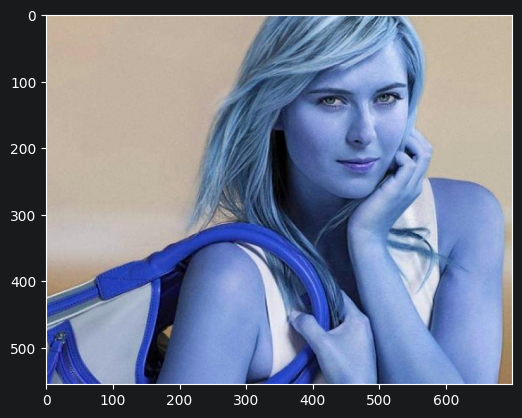

In [3]:
plt.imshow(img)

In [4]:
grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
grey.shape

(555, 700)

In [5]:
grey

array([[175, 175, 175, ..., 176, 175, 174],
       [175, 175, 175, ..., 177, 175, 174],
       [175, 175, 175, ..., 177, 176, 174],
       ...,
       [ 84,  87,  88, ..., 113, 113, 113],
       [ 88,  89,  90, ..., 113, 113, 113],
       [ 93,  91,  91, ..., 112, 112, 112]], shape=(555, 700), dtype=uint8)

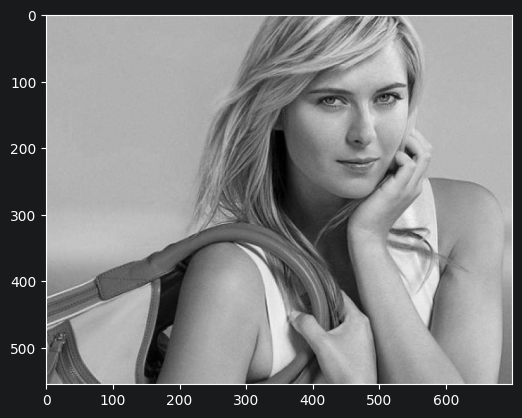

In [6]:
plt.imshow(grey, cmap="gray")

In [7]:
face_cascade = cv2.CascadeClassifier("./opencv/haarcascades/haarcascade_frontalface_default.xml")
eye_cascade = cv2.CascadeClassifier("./opencv/haarcascades/haarcascade_eye.xml")

faces = face_cascade.detectMultiScale(grey, 1.3, 5)
faces

array([[352,  38, 233, 233]], dtype=int32)

In [8]:
(x, y, w, h) = faces[0]
x, y, w, h

(np.int32(352), np.int32(38), np.int32(233), np.int32(233))

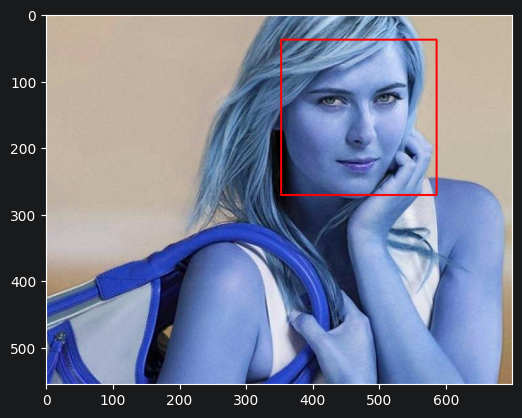

In [9]:
face_img = cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 0), 2)
plt.imshow(face_img)

[[134  65  47  47]
 [ 50  68  48  48]]


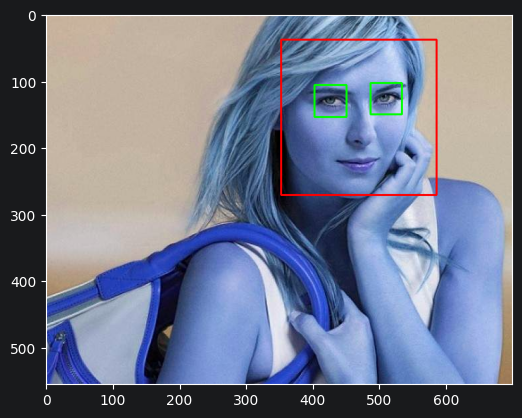

In [10]:
# detecting eyes
cv2.destroyAllWindows()
for (x, y, w, h) in faces:
    face_img = cv2.rectangle(img, (x,y), (x + w, y + h), (255, 0, 0), 2)
    roi_grey = grey[y:y + h, x:x + w]
    roi_color = face_img[y:y + h, x:x + w]
    eyes = eye_cascade.detectMultiScale(roi_grey)
    print(eyes)
    for (ex, ey, ew, eh) in eyes:
        cv2.rectangle(roi_color, (ex, ey), (ex + ew, ey + eh), (0, 255, 0), 2)

plt.figure()
plt.imshow(face_img, cmap="gray")
plt.show()

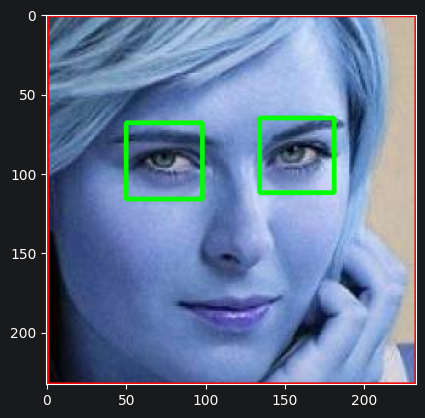

In [11]:
plt.imshow(roi_color, cmap="gray")

In [12]:
def get_cropped_image_if_2_eyes(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.3, 5)
    for (x, y, w, h) in faces:
        roi_gray = gray[y:y + h, x:x + w]
        roi_color = img[y:y + h, x:x + w]
        eyes = eye_cascade.detectMultiScale(roi_gray)
        if len(eyes) >= 2:
           return roi_color

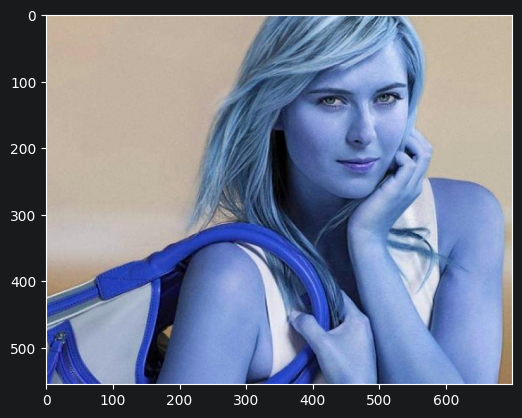

In [13]:
original_image = cv2.imread("./sharapova.jpg")
plt.imshow(original_image)

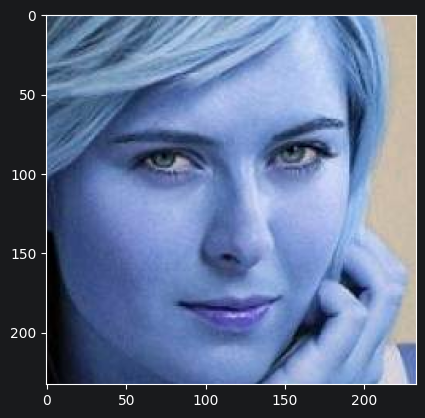

In [14]:
cropped_image = get_cropped_image_if_2_eyes("./sharapova.jpg")
plt.imshow(cropped_image)

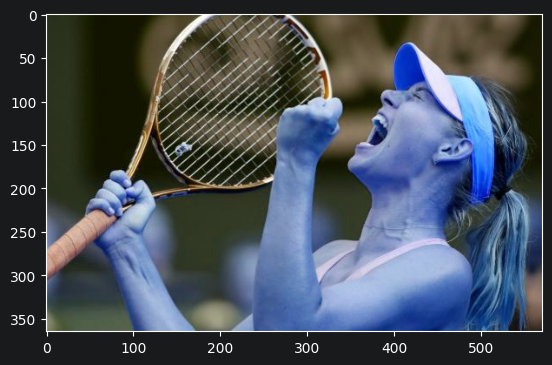

In [15]:
 org_image_obstructed = cv2.imread("./sharapova2.JPG")
 plt.imshow(org_image_obstructed)

In [16]:
cropped_image_no_2_eyes = get_cropped_image_if_2_eyes("./sharapova2.JPG")
cropped_image_no_2_eyes

In [17]:
path_to_data = "./image_dataset"
path_to_cropped_data = "./image_dataset/cropped"

In [18]:
import os
img_dirs = []
for entry in os.scandir(path_to_data):
    if entry.is_dir():
        img_dirs.append(entry.path)

img_dirs

['./image_dataset\\lionel_messi',
 './image_dataset\\maria_sharapova',
 './image_dataset\\roger_federer',
 './image_dataset\\serena_williams',
 './image_dataset\\virat_kohli']

In [19]:
import shutil
if os.path.exists(path_to_cropped_data):
    shutil.rmtree(path_to_cropped_data)

os.mkdir(path_to_cropped_data)

In [20]:
cropped_image_dirs = []
celebrity_file_names_dict = {}

for img_dir in img_dirs:
    count = 1
    celebrity_name = img_dir.split("\\")[-1]
    print(celebrity_name)

    celebrity_file_names_dict[celebrity_name] = []

    for entry in os.scandir(img_dir):
        roi_color = get_cropped_image_if_2_eyes(entry.path)
        if roi_color is not None:
            cropped_folder = path_to_cropped_data + "\\" + celebrity_name
            if not os.path.exists(cropped_folder):
                os.mkdir(cropped_folder)
                cropped_image_dirs.append(cropped_folder)
                print("Generating cropped images for " + cropped_folder)

            cropped_file_name = celebrity_name + str(count) + ".png"
            cropped_file_path = cropped_folder + "\\" + cropped_file_name

            cv2.imwrite(cropped_file_path, roi_color)
            celebrity_file_names_dict[celebrity_name].append(cropped_file_path)
            count += 1

lionel_messi
Generating cropped images for ./image_dataset/cropped\lionel_messi
maria_sharapova
Generating cropped images for ./image_dataset/cropped\maria_sharapova
roger_federer
Generating cropped images for ./image_dataset/cropped\roger_federer
serena_williams
Generating cropped images for ./image_dataset/cropped\serena_williams
virat_kohli
Generating cropped images for ./image_dataset/cropped\virat_kohli


In [21]:
# wavelet transformation
import pywt

def w2d(img, mode="haar", level=1):
    im_arr = img
    #Datatype conversion, convert to grayscale
    im_arr = cv2.cvtColor(im_arr, cv2.COLOR_BGR2GRAY)

    im_arr = np.float32(im_arr)
    im_arr /= 255

    coeffs = pywt.wavedec2(im_arr, mode, level=level)

    #Process Coefficient
    coeffs_H = list(coeffs)
    coeffs_H[0] *= 0

    #Reconstruction
    im_arr_H = pywt.waverec2(coeffs_H, mode)
    im_arr_H *= 255
    im_arr_H = np.uint8(im_arr_H)
    return im_arr_H

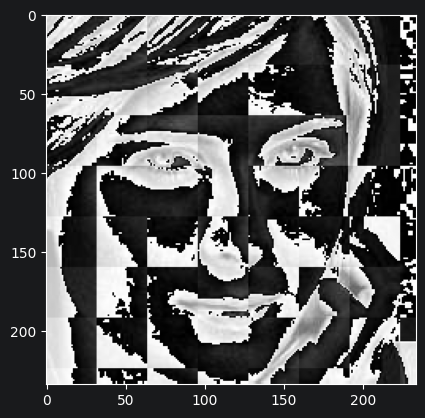

In [22]:
im_har = w2d(cropped_image, "db1", 5)
plt.imshow(im_har, cmap="gray")

In [23]:
celebrity_file_names_dict

{'lionel_messi': ['./image_dataset/cropped\\lionel_messi\\lionel_messi1.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi2.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi3.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi4.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi5.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi6.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi7.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi8.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi9.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi10.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi11.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi12.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi13.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi14.png',
  './image_dataset/cropped\\lionel_messi\\lionel_messi15.png',
  './image_dataset/cropped\\lionel_messi\\lionel

In [24]:
class_dict = {}
count = 0
for celebrity_name in celebrity_file_names_dict.keys():
    class_dict[celebrity_name] = count
    count = count + 1

class_dict

{'lionel_messi': 0,
 'maria_sharapova': 1,
 'roger_federer': 2,
 'serena_williams': 3,
 'virat_kohli': 4}

In [25]:
X = []
y = []
for celebrity_name, training_files in celebrity_file_names_dict.items():
    for training_image in training_files:
        img = cv2.imread(training_image)
        if img is None:
            continue
        scalled_raw_img = cv2.resize(img, (32, 32))
        img_har = w2d(img, "db1", 5)
        scalled_img_har = cv2.resize(img_har, (32, 32))
        combined_img = np.vstack((scalled_raw_img.reshape(32 * 32 * 3, 1), scalled_img_har.reshape(32 * 32, 1)))
        X.append(combined_img)
        y.append(class_dict[celebrity_name])

In [26]:
len(X)

187

In [27]:
X = np.array(X).reshape(len(X), 4096).astype(float)
X.shape

(187, 4096)

In [28]:
X[0]

array([100., 129., 140., ..., 238., 232., 230.], shape=(4096,))

In [29]:
# Model Training
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
pipe = Pipeline([("scaler", StandardScaler()),("svc", SVC(kernel="rbf", C = 10))])
pipe.fit(X_train, y_train)
pipe.score(X_test, y_test)

0.8723404255319149

In [31]:
len(X_test)

47

In [32]:
print(classification_report(y_test,pipe.predict(X_test)))

              precision    recall  f1-score   support

           0       0.89      0.80      0.84        10
           1       0.89      1.00      0.94         8
           2       1.00      0.67      0.80         6
           3       0.90      0.82      0.86        11
           4       0.80      1.00      0.89        12

    accuracy                           0.87        47
   macro avg       0.90      0.86      0.87        47
weighted avg       0.88      0.87      0.87        47



In [33]:
# GridSearchCv
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV

In [34]:
model_params = {
    "svm": {
        "model": svm.SVC(gamma = "auto", probability = True),
        "params" : {
            "svc__C" : [1, 10, 100, 1000],
            "svc__kernel": ["rbf", "linear"]
        }
    },
    "random_forest": {
        "model": RandomForestClassifier(),
        "params" : {
            "randomforestclassifier__n_estimators": [1, 5, 10]
        }
    },
    "logistic_regression": {
        "model": LogisticRegression(solver="liblinear", multi_class='auto'),
        "params" : {
            "logisticregression__C" : [1, 5, 10]
        }
    }
}

In [35]:
scores = []
best_estimators = {}
import pandas as pd
for algo, mp in model_params.items():
    pipe = make_pipeline(StandardScaler(), mp["model"])
    clf = GridSearchCV(pipe, mp["params"], cv = 5, return_train_score = False)
    clf.fit(X_train, y_train)
    scores.append({
        "model": algo,
        "best_score": clf.best_score_,
        "best_params": clf.best_params_,
    })
    best_estimators[algo] = clf.best_estimator_

df = pd.DataFrame(scores, columns=["model", "best_score", "best_params"])
df

D:\Data Science\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
D:\Data Science\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1296: FutureWarning: Using the 'liblinear' solver for multiclass classification is deprecated. An error will be raised in 1.8. Either use another solver which supports the multinomial loss or wrap the estimator in a OneVsRestClassifier to keep applying a one-versus-rest scheme.
  warnings.warn(
D:\Data Science\.venv\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
D:\Data Science\.venv\lib\site-packages\sklearn\linear_model

,model,best_score,best_params
0,svm,0.735714,"{'svc__C': 10, 'svc__kernel': 'rbf'}"
1,random_forest,0.664286,{'randomforestclassifier__n_estimators': 10}
2,logistic_regression,0.742857,{'logisticregression__C': 1}


In [36]:
best_estimators["svm"].score(X_test, y_test)

0.8723404255319149

In [37]:
best_estimators["random_forest"].score(X_test, y_test)

0.7021276595744681

In [38]:
best_estimators["logistic_regression"].score(X_test, y_test)

0.851063829787234

In [39]:
best_clf = best_estimators["svm"]
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, best_clf.predict(X_test))
cm

array([[ 8,  0,  0,  1,  1],
       [ 0,  8,  0,  0,  0],
       [ 1,  0,  4,  0,  1],
       [ 0,  1,  0,  9,  1],
       [ 0,  0,  0,  0, 12]])

Text(95.72222222222221, 0.5, 'True label')

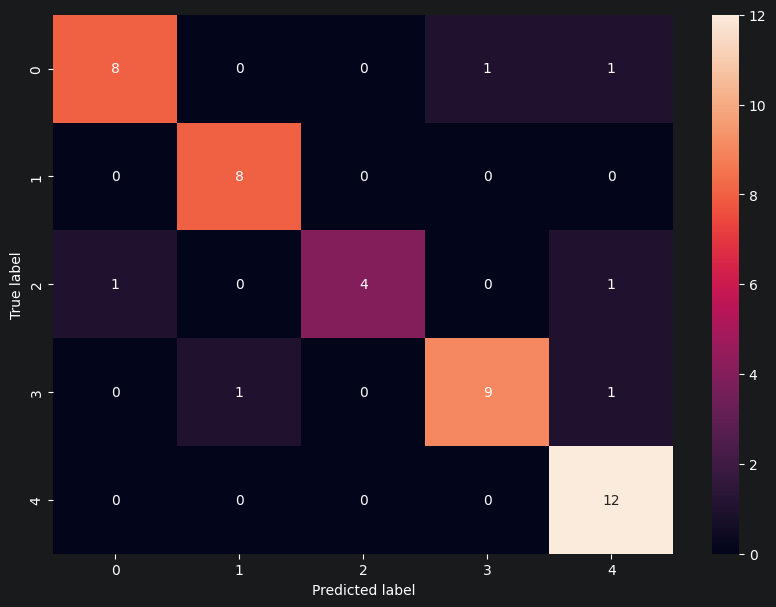

In [40]:
import seaborn as sn
plt.figure(figsize=(10, 7))
sn.heatmap(cm, annot = True)
plt.xlabel("Predicted label")
plt.ylabel("True label")

In [41]:
class_dict

{'lionel_messi': 0,
 'maria_sharapova': 1,
 'roger_federer': 2,
 'serena_williams': 3,
 'virat_kohli': 4}